# LS4SRec: reproduction + User-Adaptive Popularity-Aware extension

**Base paper:** *Self-supervised Graph Neural Sequential Recommendation with Disentangling Long and Short-Term Interest* (He et al., ACM TORS 2026). Authors' code: https://github.com/jiubaoyibao/LS4SRec

**What this notebook does**
1. Loads the outputs of the trained LS4SRec model (trained on an Apple M3 Pro; best validation epoch 48).
2. Shows the reproduction result against the paper.
3. Runs the extension experiments E1–E4: popularity-aware re-ranking of LS4SRec's scores.
4. Shows all result tables, a significance test, and the charts.

**How to run:** put the project files in a Google Drive folder named `LS4SRec_Project` (including `model_outputs.npz`; it may have another name, e.g. after WhatsApp — the setup cell finds it). Then **Runtime → Run all**. No GPU is needed; it takes about 15 minutes. Results are also saved to `LS4SRec_Project/colab_results/` in Drive.

The training code itself (hours on a GPU) is shown in the appendix at the end.

## 0. Setup
Connect Google Drive, copy the project files into Colab, find the model-outputs file, and download the authors' dataset.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

# copy the project files into Colab, removing "Copy of " that Google Drive adds to copied files
!cd "/content/drive/MyDrive/LS4SRec_Project" && for f in *; do cp -r "$f" "/content/${f#Copy of }"; done

# find the model outputs file (it may have been renamed, e.g. by WhatsApp, or still be inside the project zip)
import os, glob, zipfile, shutil
if not os.path.exists('/content/model_outputs.npz'):
    for path in glob.glob('/content/*'):
        if os.path.isfile(path) and zipfile.is_zipfile(path):
            names = zipfile.ZipFile(path).namelist()
            if 'item_vectors.npy' in names:
                shutil.copy(path, '/content/model_outputs.npz')
                break
            inner = [n for n in names if n.endswith('model_outputs.npz')]
            if inner:
                open('/content/model_outputs.npz', 'wb').write(zipfile.ZipFile(path).read(inner[0]))
                break
print('model_outputs.npz found:', os.path.exists('/content/model_outputs.npz'))

# the authors' code and Home & Kitchen data, at the exact version used
!git clone -q https://github.com/jiubaoyibao/LS4SRec.git /content/LS4SRec 2>/dev/null
!git -C /content/LS4SRec checkout -q 2db58eb4ea5ec01db1bf85aae459ef7f74e82fb4
print('dataset files:', sorted(os.listdir('/content/LS4SRec/datasets/home')))

Mounted at /content/drive
model_outputs.npz found: True
dataset files: ['all_train_seq.txt', 'home.txt', 'test.pkl', 'train.pkl', 'valid.pkl', 'witg.pt']


## 1. Reproduction: training curve
Validation HR@20 and NDCG@20 after every training epoch (from `history.csv`). Training used early stopping on validation NDCG@20 with patience 10: the best epoch was **48**, and training stopped after epoch 58.

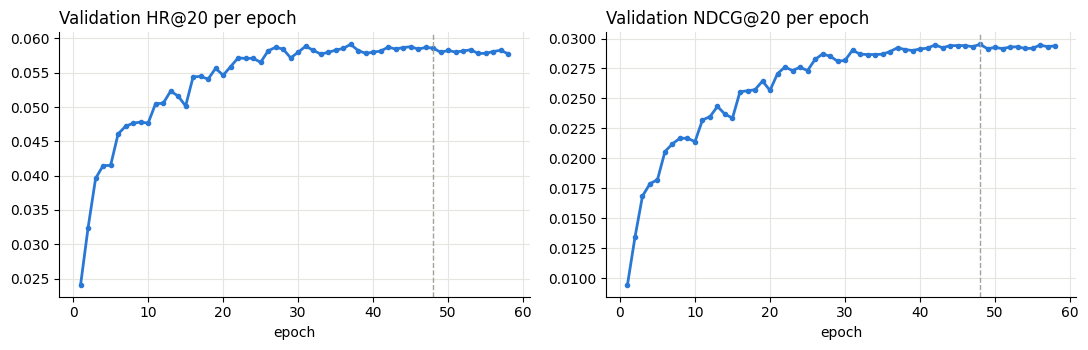

best epoch: 48 | validation HR@20 0.0586 | validation NDCG@20 0.0295


In [2]:
import os
import pandas as pd
import matplotlib.pyplot as plt
if os.path.exists('/content/history.csv'):
    history = pd.read_csv('/content/history.csv')
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
    axes[0].plot(history['epoch'], history['val_HR@20'], '-o', color='#2a78d6', ms=3, lw=2)
    axes[0].set_title('Validation HR@20 per epoch', loc='left')
    axes[1].plot(history['epoch'], history['val_NDCG@20'], '-o', color='#2a78d6', ms=3, lw=2)
    axes[1].set_title('Validation NDCG@20 per epoch', loc='left')
    best = history.loc[history['val_NDCG@20'].idxmax()]
    for a in axes:
        a.axvline(best['epoch'], color='#a3a29b', ls='--', lw=1)
        a.set_xlabel('epoch')
        a.grid(color='#e6e5e0', lw=0.8)
        a.spines[['top', 'right']].set_visible(False)
    plt.tight_layout()
    plt.show()
    print('best epoch:', int(best['epoch']), '| validation HR@20', round(best['val_HR@20'], 4),
          '| validation NDCG@20', round(best['val_NDCG@20'], 4))
else:
    print('history.csv not found in the Drive folder - skipping the training curve')

## 2. The extension: user-adaptive popularity-aware re-ranking
All variants re-rank the **same trained model's scores** (no retraining). For user *u* and candidate item *v*:

- item popularity (training data only): $q_v = \log(1+c_v) / \max_v \log(1+c_v)$
- user's taste for popular items: $q_u$ = average $q_v$ of the user's training items
- adjusted score: $s'_{u,v} = s_{u,v} - \beta_u \, q_v$

| Variant | $\beta_u$ |
|---|---|
| E1 | 0 (original LS4SRec) |
| E2 | $\beta_{max}$ for every user (fixed penalty) |
| **E3** | $\beta_{max}(1-q_u)$ — **the proposed method** |
| E3-rank | $\beta_{max}(1-\text{rank}(q_u))$, rank = percentile among users |
| E3-rank-shrink | as E3-rank, short histories pulled toward the average first |
| E4 | as E3-rank, but taste mixes full history and last 3 items using the model's α |

**Selection rule (fixed before looking at results):** for each variant, $\beta_{max}$ is chosen on the **validation** set as the value with the highest long-tail Recall@10 while keeping Recall@10 ≥ 95% of E1. Each choice is then evaluated **once** on the test set.

### 2.1 Settings

In [3]:
import sys, json, pickle
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import display

NPZ = Path('/content/model_outputs.npz')                       # saved outputs of the trained LS4SRec
DATA = Path('/content/LS4SRec/datasets/home')                  # authors' Home & Kitchen data
OUT = Path('/content/drive/MyDrive/LS4SRec_Project/colab_results')   # results are also saved here
OUT.mkdir(parents=True, exist_ok=True)
ACCURACY_KEEP = 0.95          # selection rule: keep at least 95% of E1's Recall@10 on validation
HEAD_SHARE = 0.20             # "popular" = top 20% of items by training purchases; the rest is "long tail"
SHRINK_STRENGTH = 5           # E3-rank-shrink: a user with n items gets weight n/(n+5) on their own taste
SHORT_K = 3                   # E4: short-term taste = last 3 training items (same k as the paper)
GRID_MULTIPLIERS = [0.05, 0.1, 0.2, 0.35, 0.5, 0.75, 1.0, 1.5, 2.0, 3.0, 4.0, 5.0, 6.0, 8.0, 10.0]   # beta_max values = these x typical score spread
BATCH = 1024
torch.set_grad_enabled(False)

torch.autograd.grad_mode.set_grad_enabled(mode=False)

### 2.2 Load the model outputs and the data

In [4]:
# ---------------------------------------------------------------- 1. Load model outputs and data
out = np.load(NPZ)
item_vectors = torch.from_numpy(out['item_vectors'])
N_ITEMS = item_vectors.shape[0]
print('model outputs from checkpoint epoch', int(out['checkpoint_epoch']), '| items', N_ITEMS)

train_seqs = {}
for line in (DATA / 'all_train_seq.txt').read_text().splitlines():
    uid, items = line.split(' ', 1)
    train_seqs[int(uid)] = [int(x) for x in items.split(',')]
full_seqs = {}
for line in (DATA / 'home.txt').read_text().splitlines():
    uid, items = line.split(' ', 1)
    full_seqs[int(uid)] = [int(x) for x in items.split(',')]
N_USERS = len(full_seqs)

model outputs from checkpoint epoch 48 | items 28238


### 2.3 Step 1 – item popularity
Using training purchases only (no leakage). "Long tail" = items outside the top 20% by purchases.

In [5]:
# ---------------------------------------------------------------- 2. Step 1 of her method: item popularity (training data only)
counts = np.zeros(N_ITEMS)
for seq in train_seqs.values():
    for item in seq:
        counts[item] += 1
q_item = np.log1p(counts) / np.log1p(counts).max()          # 0 = never bought, 1 = most popular
item_order = np.argsort(-counts[1:], kind='stable') + 1                     # item ids, most popular first (0 = padding)
n_head = int(round(HEAD_SHARE * (N_ITEMS - 1)))
is_tail = np.ones(N_ITEMS, dtype=bool)
is_tail[item_order[:n_head]] = False
is_tail[0] = False
print(f'popular (head) items: {n_head} | long-tail items: {is_tail.sum()}')

popular (head) items: 5647 | long-tail items: 22590


### 2.4 Step 2 – each user's taste for popular items

In [6]:
# ---------------------------------------------------------------- 3. Step 2: each user's taste for popular items (training data only)
hist_len = np.array([len(train_seqs[u]) for u in range(N_USERS)])
q_user_raw = np.array([q_item[train_seqs[u]].mean() for u in range(N_USERS)])
q_user_short = np.array([q_item[train_seqs[u][-SHORT_K:]].mean() for u in range(N_USERS)])
# percentile rank across users: 0 = most niche user, 1 = most popular-loving user
q_user_rank = np.argsort(np.argsort(q_user_raw, kind='stable'), kind='stable') / (N_USERS - 1)
# shrink short histories toward the average taste, then rank
q_user_shrunk = (hist_len * q_user_raw + SHRINK_STRENGTH * q_user_raw.mean()) / (hist_len + SHRINK_STRENGTH)
q_user_shrunk_rank = np.argsort(np.argsort(q_user_shrunk, kind='stable'), kind='stable') / (N_USERS - 1)
length_group = np.where(hist_len <= 5, 'short (<=5)', np.where(hist_len <= 10, 'medium (6-10)', 'long (>10)'))
print('raw q_user percentiles 10/50/90:', np.round(np.percentile(q_user_raw, [10, 50, 90]), 3))
pd.DataFrame({'user': np.arange(N_USERS), 'history_length': hist_len, 'q_user_raw': q_user_raw,
              'q_user_short': q_user_short, 'q_user_rank': q_user_rank,
              'q_user_shrunk_rank': q_user_shrunk_rank}).to_csv(OUT / 'user_popularity_taste.csv', index=False)

raw q_user percentiles 10/50/90: [0.384 0.496 0.617]


### 2.5 Range of penalty strengths to try
$\beta_{max}$ values are multiples of the typical spread of a user's scores, so the penalty is on the same scale as the scores.

In [7]:
# ---------------------------------------------------------------- 4. Typical score spread, used to set the beta_max grid
sample = torch.from_numpy(out['valid_user_vectors'][:2000]) @ item_vectors.T
score_spread = float(sample[:, 1:].std(dim=1).median())
beta_grid = [round(m * score_spread, 4) for m in GRID_MULTIPLIERS]
print(f'typical per-user score spread (std): {score_spread:.3f} -> beta_max grid {beta_grid}')

variants = ['E2', 'E3', 'E3-rank', 'E3-rank-shrink', 'E4']
q_item_t = torch.from_numpy(q_item).float()
is_tail_t = torch.from_numpy(is_tail)
discount10 = 1 / torch.log2(torch.arange(2, 12).float())
discount20 = 1 / torch.log2(torch.arange(2, 22).float())
all_rows = []
chosen = {}

typical per-user score spread (std): 1.413 -> beta_max grid [0.0706, 0.1413, 0.2826, 0.4945, 0.7065, 1.0597, 1.413, 2.1195, 2.826, 4.239, 5.652, 7.065, 8.4779, 11.3039, 14.1299]


### 2.6 Steps 3–4 – penalties, re-ranking and evaluation
First every variant × $\beta_{max}$ on **validation**, then pick $\beta_{max}$ per variant with the rule above, then run each choice once on **test**. This is the slow cell (about 10–15 minutes on Colab's CPU).

In [8]:
# ---------------------------------------------------------------- 5. Evaluate: validation grid first, then test with chosen beta_max
for split in ['valid', 'test']:
    uids = out[split + '_uids']
    targets = out[split + '_targets']
    user_vectors = torch.from_numpy(out[split + '_user_vectors'])
    alpha = np.clip(out[split + '_alpha'], 0, 1)          # model's long-term weight, clipped to 0..1
    n = len(uids)

    # E4 taste: alpha * long-term taste + (1 - alpha) * short-term taste, then percentile rank
    q_mix = alpha * q_user_raw[uids] + (1 - alpha) * q_user_short[uids]
    q_mix_rank = np.argsort(np.argsort(q_mix, kind='stable'), kind='stable') / (n - 1)
    taste = {'E2': np.zeros(n), 'E3': q_user_raw[uids], 'E3-rank': q_user_rank[uids],
             'E3-rank-shrink': q_user_shrunk_rank[uids], 'E4': q_mix_rank}

    # list of configurations (variant, beta_max) to run on this split
    configs = [('E1', 0.0)]
    for v in variants:
        if split == 'valid':
            configs += [(v, b) for b in beta_grid]
        else:
            configs += [(v, chosen[v])]

    # Step 3: per-user penalty strength beta_u for every configuration
    beta_u = {}
    for v, b in configs:
        if v == 'E1':
            beta_u[(v, b)] = torch.zeros(n)
        elif v == 'E2':
            beta_u[(v, b)] = torch.full((n,), b)
        else:
            beta_u[(v, b)] = torch.from_numpy(b * (1 - taste[v])).float()

    # items to hide from ranking: training items for validation; training items + validation item for test
    seen_items = [train_seqs[u] if split == 'valid' else full_seqs[u][:-1] for u in uids]

    stats = {c: {'hit10': 0.0, 'ndcg10': 0.0, 'hit20': 0.0, 'ndcg20': 0.0, 'tail_hit10': 0.0, 'pop10': 0.0,
                 'count10': 0.0, 'tail_recs10': 0.0, 'covered': torch.zeros(N_ITEMS, dtype=torch.bool),
                 'group_hit10': {}, 'group_tail_hit10': {}, 'per_user_hit10': []} for c in configs}
    target_is_tail = is_tail[targets]
    groups = length_group[uids]

    for start in range(0, n, BATCH):
        end = min(start + BATCH, n)
        scores = user_vectors[start:end] @ item_vectors.T
        scores[:, 0] = -torch.inf
        rows = np.concatenate([np.full(len(seen_items[i]), i - start) for i in range(start, end)])
        cols = np.concatenate([seen_items[i] for i in range(start, end)])
        scores[torch.from_numpy(rows), torch.from_numpy(np.array(cols))] = -torch.inf
        batch_targets = torch.from_numpy(targets[start:end])
        batch_tail = torch.from_numpy(target_is_tail[start:end])
        batch_groups = groups[start:end]

        for c in configs:
            # Step 4: adjusted score = score - beta_u * q_item
            adjusted = scores - beta_u[c][start:end, None] * q_item_t[None, :]
            top = adjusted.topk(20, dim=1).indices
            hits = top.eq(batch_targets[:, None]).float()
            s = stats[c]
            s['hit10'] += hits[:, :10].sum().item()
            s['ndcg10'] += (hits[:, :10] * discount10).sum().item()
            s['hit20'] += hits.sum().item()
            s['ndcg20'] += (hits * discount20).sum().item()
            hit10_per_user = hits[:, :10].sum(1)
            s['per_user_hit10'].append(hit10_per_user.numpy())
            s['tail_hit10'] += (hit10_per_user * batch_tail).sum().item()
            s['pop10'] += q_item_t[top[:, :10]].sum().item()
            s['count10'] += float(counts[top[:, :10].numpy()].sum())
            s['tail_recs10'] += is_tail_t[top[:, :10]].sum().item()
            s['covered'][top[:, :10].flatten()] = True
            for g in ['short (<=5)', 'medium (6-10)', 'long (>10)']:
                in_group = torch.from_numpy(batch_groups == g)
                s['group_hit10'][g] = s['group_hit10'].get(g, 0.0) + (hit10_per_user * in_group).sum().item()
                s['group_tail_hit10'][g] = s['group_tail_hit10'].get(g, 0.0) + \
                    (hit10_per_user * in_group * batch_tail).sum().item()

    # turn sums into metrics
    for v, b in configs:
        s = stats[(v, b)]
        row = {'split': split, 'variant': v, 'beta_max': b,
               'beta_max_x_spread': round(b / score_spread, 3),
               'Recall@10': s['hit10'] / n, 'NDCG@10': s['ndcg10'] / n,
               'Recall@20': s['hit20'] / n, 'NDCG@20': s['ndcg20'] / n,
               'LongTail_Recall@10': s['tail_hit10'] / target_is_tail.sum(),
               'Coverage@10': s['covered'][1:].float().mean().item(),
               'AvgPopularity@10 (q)': s['pop10'] / (10 * n),
               'AvgPurchases@10': s['count10'] / (10 * n),
               'LongTail_share_of_recs@10': s['tail_recs10'] / (10 * n)}
        for g in ['short (<=5)', 'medium (6-10)', 'long (>10)']:
            in_group = groups == g
            row[f'Recall@10 {g}'] = s['group_hit10'][g] / in_group.sum()
            row[f'LongTail_Recall@10 {g}'] = s['group_tail_hit10'][g] / (in_group & target_is_tail).sum()
        all_rows.append(row)

    # selection on validation only
    if split == 'valid':
        grid = pd.DataFrame([r for r in all_rows if r['split'] == 'valid'])
        e1_recall = grid.loc[grid.variant == 'E1', 'Recall@10'].item()
        for v in variants:
            options = grid[(grid.variant == v) & (grid['Recall@10'] >= ACCURACY_KEEP * e1_recall)]
            if len(options) == 0:
                chosen[v] = min(beta_grid)
            else:
                chosen[v] = options.sort_values('LongTail_Recall@10', ascending=False, kind='stable').iloc[0]['beta_max']
        print('chosen beta_max per variant (validation):', chosen)
        for v in variants:
            if chosen[v] == max(beta_grid):
                print(f'WARNING: {v} chose the largest beta_max in the grid; extend GRID_MULTIPLIERS', flush=True)
    if split == 'test':
        test_hits = {v: np.concatenate(stats[(v, b)]['per_user_hit10']) for v, b in configs}
        test_tail = target_is_tail.copy()
    print(f'{split} done', flush=True)

chosen beta_max per variant (validation): {'E2': np.float64(2.826), 'E3': np.float64(7.065), 'E3-rank': np.float64(7.065), 'E3-rank-shrink': np.float64(7.065), 'E4': np.float64(7.065)}
valid done
test done


### 2.7 Result tables, significance test, and saving
**Significance test:** paired bootstrap over test users (1000 resamples). If the 95% interval of a difference excludes 0, the difference is unlikely to be noise.

In [9]:
# ---------------------------------------------------------------- 6. Save tables
results = pd.DataFrame(all_rows)
results[results.split == 'valid'].to_csv(OUT / 'validation_grid.csv', index=False)
test_table = results[results.split == 'test'].copy()
e1 = test_table[test_table.variant == 'E1'].iloc[0]
for metric in ['Recall@10', 'NDCG@10', 'LongTail_Recall@10', 'Coverage@10', 'AvgPopularity@10 (q)']:
    test_table[metric + ' change vs E1 (%)'] = 100 * (test_table[metric] / e1[metric] - 1)
test_table.to_csv(OUT / 'test_results.csv', index=False)

valid_table = results[results.split == 'valid']
valid_chosen = pd.concat([valid_table[valid_table.variant == 'E1']] +
                         [valid_table[(valid_table.variant == v) & (valid_table.beta_max == chosen[v])] for v in variants])
winner = valid_chosen[valid_chosen.variant != 'E1'].sort_values('LongTail_Recall@10', ascending=False).iloc[0]['variant']

# Paired bootstrap on TEST users: resample users 1000 times, recompute the difference between two variants.
# If the 95% interval excludes 0, the difference is unlikely to be noise.
pairs = [(v, 'E1') for v in variants] + [(v, 'E2') for v in ['E3', 'E3-rank', 'E3-rank-shrink', 'E4']] + \
        [('E3-rank', 'E3'), ('E3-rank-shrink', 'E3-rank'), ('E4', 'E3-rank'), ('E4', 'E3')]
rng = np.random.default_rng(0)
n_test = len(test_tail)
boot = {(a, b, m): [] for a, b in pairs for m in ['Recall@10', 'LongTail_Recall@10']}
for r in range(1000):
    idx = rng.integers(0, n_test, n_test)
    tail_idx = test_tail[idx]
    for a, b in pairs:
        d = test_hits[a][idx] - test_hits[b][idx]
        boot[(a, b, 'Recall@10')].append(d.mean())
        boot[(a, b, 'LongTail_Recall@10')].append(d[tail_idx].sum() / tail_idx.sum())
sig_rows = []
for a, b in pairs:
    for m in ['Recall@10', 'LongTail_Recall@10']:
        if m == 'Recall@10':
            observed = (test_hits[a] - test_hits[b]).mean()
        else:
            observed = (test_hits[a] - test_hits[b])[test_tail].sum() / test_tail.sum()
        low, high = np.percentile(boot[(a, b, m)], [2.5, 97.5])
        sig_rows.append({'comparison': f'{a} vs {b}', 'metric': m, 'difference': observed,
                         'ci95_low': low, 'ci95_high': high,
                         'significant': 'yes' if (low > 0 or high < 0) else 'no'})
significance = pd.DataFrame(sig_rows)
significance.to_csv(OUT / 'significance_test.csv', index=False)

main_cols = ['variant', 'beta_max', 'Recall@10', 'NDCG@10', 'Recall@20', 'NDCG@20', 'LongTail_Recall@10',
             'Coverage@10', 'AvgPopularity@10 (q)', 'AvgPurchases@10']
group_cols = ['variant'] + [c for c in test_table.columns if (c.startswith('Recall@10 ') or c.startswith('LongTail_Recall@10 ')) and 'change' not in c]
summary = []
summary.append('LS4SRec popularity-aware re-ranking: results')
summary.append(f'model checkpoint epoch: {int(out["checkpoint_epoch"])}')
summary.append(f'selection rule: per variant, highest validation LongTail_Recall@10 with Recall@10 >= {ACCURACY_KEEP:.0%} of E1')
summary.append(f'validation winner (chosen before looking at test): {winner}')
summary.append('\nVALIDATION (chosen beta_max per variant)\n' + valid_chosen[main_cols].to_string(index=False, float_format='%.4f'))
summary.append('\nTEST\n' + test_table[main_cols].to_string(index=False, float_format='%.4f'))
summary.append('\nTEST: change vs E1 (%)\n' + test_table[['variant'] + [c for c in test_table.columns if 'change vs E1' in c]]
               .to_string(index=False, float_format='%.1f'))
summary.append('\nTEST by history length\n' + test_table[group_cols].to_string(index=False, float_format='%.4f'))
summary.append('\nTEST significance (paired bootstrap, 1000 resamples of users; difference = first minus second)\n'
               + significance.to_string(index=False, float_format='%.5f'))
(OUT / 'summary.txt').write_text('\n'.join(summary))
json.dump({'chosen_beta_max': chosen, 'winner_on_validation': winner, 'score_spread': score_spread},
          open(OUT / 'choices.json', 'w'), indent=2)
print('All result files saved to', OUT)

All result files saved to /content/drive/MyDrive/LS4SRec_Project/colab_results


## 3. Results
### 3.1 Reproduction: original LS4SRec (E1) on the test set vs the paper

In [10]:
e1_test = test_table[test_table.variant == 'E1'].iloc[0]
reproduction = pd.DataFrame({'Metric': ['HR@20', 'NDCG@20'],
                             'Paper (Table 2, Home)': [0.0477, 0.0237],
                             'This reproduction': [e1_test['Recall@20'], e1_test['NDCG@20']]})
reproduction['Difference (%)'] = 100 * (reproduction['This reproduction'] / reproduction['Paper (Table 2, Home)'] - 1)
display(reproduction.round(4))
print('(In next-item prediction there is one correct item per user, so HR@20 = Recall@20.)')

,Metric,"Paper (Table 2, Home)",This reproduction,Difference (%)
0,HR@20,0.0477,0.0468,-1.8896
1,NDCG@20,0.0237,0.0235,-0.8665


(In next-item prediction there is one correct item per user, so HR@20 = Recall@20.)


### 3.2 Test results for every variant

In [11]:
print('Chosen beta_max per variant (on validation):', {k: round(float(v), 3) for k, v in chosen.items()})
print('Variant picked by the selection rule on validation:', winner)
display(test_table[main_cols].round(4))

Chosen beta_max per variant (on validation): {'E2': 2.826, 'E3': 7.065, 'E3-rank': 7.065, 'E3-rank-shrink': 7.065, 'E4': 7.065}
Variant picked by the selection rule on validation: E4


,variant,beta_max,Recall@10,NDCG@10,Recall@20,NDCG@20,LongTail_Recall@10,Coverage@10,AvgPopularity@10 (q),AvgPurchases@10
76,E1,0.000,0.0332,0.0201,0.0468,0.0235,0.0163,0.5884,0.6579,152.3017
77,E2,2.826,0.0334,0.0205,0.0454,0.0236,0.0200,0.7212,0.5671,85.1230
78,E3,7.065,0.0330,0.0204,0.0443,0.0232,0.0211,0.7678,0.5397,73.1950
79,E3-rank,7.065,0.0324,0.0199,0.0441,0.0229,0.0211,0.8119,0.5355,82.0509
80,E3-rank-shrink,7.065,0.0323,0.0199,0.0441,0.0229,0.0211,0.8107,0.5356,81.9653
81,E4,7.065,0.0322,0.0200,0.0441,0.0229,0.0213,0.8071,0.5366,82.7093


### 3.3 Change vs the original model (E1), in %

In [12]:
display(test_table[['variant'] + [c for c in test_table.columns if 'change vs E1' in c]].round(1))

,variant,Recall@10 change vs E1 (%),NDCG@10 change vs E1 (%),LongTail_Recall@10 change vs E1 (%),Coverage@10 change vs E1 (%),AvgPopularity@10 (q) change vs E1 (%)
76,E1,0.0,0.0,0.0,0.0,0.0
77,E2,0.4,2.1,22.7,22.6,-13.8
78,E3,-0.7,1.3,29.7,30.5,-18.0
79,E3-rank,-2.4,-0.7,29.9,38.0,-18.6
80,E3-rank-shrink,-2.8,-0.8,29.5,37.8,-18.6
81,E4,-3.0,-0.7,30.8,37.2,-18.4


### 3.4 Significance test (test set)
`difference` = first variant minus second. `significant = yes` means the 95% interval excludes 0.

In [13]:
display(significance.round(5))

,comparison,metric,difference,ci95_low,ci95_high,significant
0,E2 vs E1,Recall@10,0.00014,-0.00056,0.00086,no
1,E2 vs E1,LongTail_Recall@10,0.00369,0.00304,0.00439,yes
2,E3 vs E1,Recall@10,-0.00023,-0.00098,0.00048,no
3,E3 vs E1,LongTail_Recall@10,0.00483,0.00410,0.00562,yes
4,E3-rank vs E1,Recall@10,-0.00080,-0.00153,-0.00004,yes
5,E3-rank vs E1,LongTail_Recall@10,0.00486,0.00412,0.00569,yes
6,E3-rank-shrink vs E1,Recall@10,-0.00095,-0.00165,-0.00018,yes
7,E3-rank-shrink vs E1,LongTail_Recall@10,0.00480,0.00406,0.00562,yes
8,E4 vs E1,Recall@10,-0.00101,-0.00173,-0.00023,yes
9,E4 vs E1,LongTail_Recall@10,0.00502,0.00424,0.00588,yes


### 3.5 Results by history length (test set)
Short = ≤5 training items (65% of users), medium = 6–10, long = >10 (about 11%).

In [14]:
display(test_table[group_cols].round(4))

,variant,Recall@10 short (<=5),LongTail_Recall@10 short (<=5),Recall@10 medium (6-10),LongTail_Recall@10 medium (6-10),Recall@10 long (>10),LongTail_Recall@10 long (>10)
76,E1,0.0315,0.0131,0.0314,0.0165,0.0475,0.0326
77,E2,0.0313,0.0165,0.0324,0.0208,0.0477,0.0367
78,E3,0.0307,0.0173,0.0321,0.0223,0.0485,0.0392
79,E3-rank,0.0300,0.0174,0.0318,0.0222,0.0483,0.0390
80,E3-rank-shrink,0.0300,0.0174,0.0312,0.0218,0.0483,0.0395
81,E4,0.0297,0.0172,0.0317,0.0220,0.0482,0.0418


### 3.6 Validation results for the chosen settings

In [15]:
display(valid_chosen[main_cols].round(4))

,variant,beta_max,Recall@10,NDCG@10,Recall@20,NDCG@20,LongTail_Recall@10,Coverage@10,AvgPopularity@10 (q),AvgPurchases@10
0,E1,0.000,0.0424,0.0254,0.0586,0.0295,0.0182,0.5989,0.6609,154.7077
9,E2,2.826,0.0414,0.0253,0.0553,0.0288,0.0223,0.7307,0.5726,87.9704
27,E3,7.065,0.0408,0.0250,0.0540,0.0283,0.0232,0.7768,0.5473,77.7918
42,E3-rank,7.065,0.0405,0.0246,0.0543,0.0281,0.0233,0.8145,0.5461,89.6362
57,E3-rank-shrink,7.065,0.0404,0.0246,0.0541,0.0280,0.0232,0.8149,0.5460,89.3227
72,E4,7.065,0.0407,0.0247,0.0543,0.0282,0.0236,0.8119,0.5481,91.1928


## 4. Charts
**Trade-off chart:** further right = more accurate, higher = more correct long-tail recommendations. Each dot is one $\beta_{max}$; circles mark the chosen setting.

**Penalty-spread chart:** how strongly each user is penalised under E3 vs E3-rank.

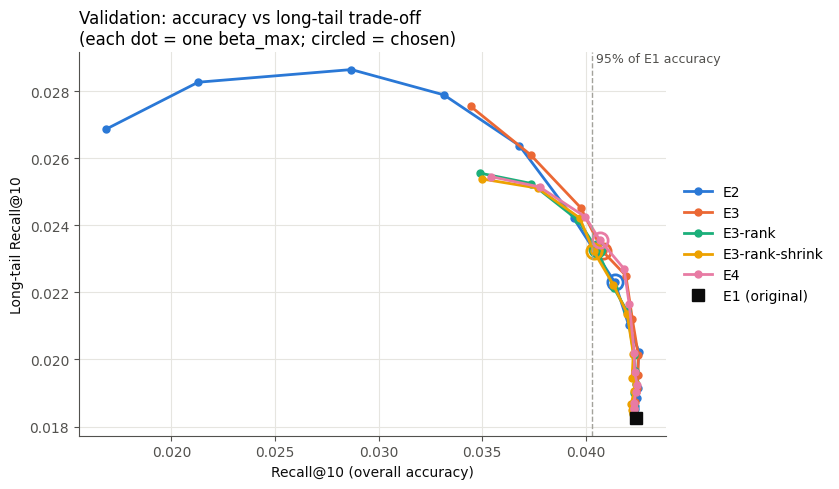

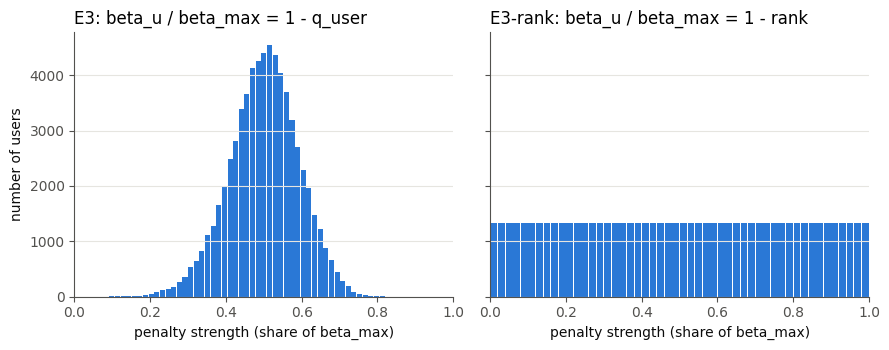

EXPERIMENTS FINISHED


In [16]:
# ---------------------------------------------------------------- 7. Charts
colors = {'E2': '#2a78d6', 'E3': '#eb6834', 'E3-rank': '#1baf7a', 'E3-rank-shrink': '#eda100', 'E4': '#e87ba4'}
plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.edgecolor': '#52514e', 'axes.labelcolor': '#0b0b0b', 'xtick.color': '#52514e',
                     'ytick.color': '#52514e'})

# Chart 1: accuracy vs long-tail trade-off on validation (one line per variant, points = beta_max values)
fig, ax = plt.subplots(figsize=(8.5, 5))
for v in variants:
    d = valid_table[valid_table.variant == v].sort_values('beta_max')
    ax.plot(d['Recall@10'], d['LongTail_Recall@10'], '-o', color=colors[v], lw=2, ms=5, label=v)
    pick = d[d.beta_max == chosen[v]]
    ax.plot(pick['Recall@10'], pick['LongTail_Recall@10'], 'o', ms=11, mfc='none', mec=colors[v], mew=2)
e1v = valid_table[valid_table.variant == 'E1'].iloc[0]
ax.plot(e1v['Recall@10'], e1v['LongTail_Recall@10'], 's', color='#0b0b0b', ms=8, label='E1 (original)')
ax.axvline(ACCURACY_KEEP * e1v['Recall@10'], color='#a3a29b', lw=1, ls='--')
ax.text(ACCURACY_KEEP * e1v['Recall@10'], ax.get_ylim()[1], f' {ACCURACY_KEEP:.0%} of E1 accuracy',
        color='#52514e', va='top', fontsize=9)
ax.set_xlabel('Recall@10 (overall accuracy)')
ax.set_ylabel('Long-tail Recall@10')
ax.set_title('Validation: accuracy vs long-tail trade-off\n(each dot = one beta_max; circled = chosen)', loc='left')
ax.grid(color='#e6e5e0', lw=0.8)
ax.legend(frameon=False, loc='center left', bbox_to_anchor=(1.01, 0.5))
fig.tight_layout()
fig.savefig(OUT / 'tradeoff_validation.png', dpi=180)
plt.show()

# Chart 2: why E3 needs the rank fix - spread of user popularity taste
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6), sharey=True)
axes[0].hist(1 - q_user_raw, bins=50, color='#2a78d6', rwidth=0.9)
axes[0].set_title('E3: beta_u / beta_max = 1 - q_user', loc='left')
axes[1].hist(1 - q_user_rank, bins=50, color='#2a78d6', rwidth=0.9)
axes[1].set_title('E3-rank: beta_u / beta_max = 1 - rank', loc='left')
for a in axes:
    a.set_xlim(0, 1)
    a.set_xlabel('penalty strength (share of beta_max)')
    a.grid(axis='y', color='#e6e5e0', lw=0.8)
axes[0].set_ylabel('number of users')
fig.tight_layout()
fig.savefig(OUT / 'penalty_spread.png', dpi=180)
plt.show()
print('EXPERIMENTS FINISHED')

## 5. Conclusions
1. **Reproduction:** test HR@20 and NDCG@20 are within about 1–2% of the paper (table 3.1).
2. **The original model favours popular items:** its top-10 items average ~152 training purchases (a typical item has ~7) and it covers ~59% of the catalogue.
3. **The proposed user-adaptive penalty (E3) works:** long-tail Recall@10 rises ~30% vs E1 and catalogue coverage rises to ~77%, with no significant loss of accuracy; its long-tail gain is significantly larger than the fixed penalty's (E2).
4. **The rank / shrink / recent-taste variants** raise coverage further (~81%) but are not significantly better than E3 on long-tail recall, and cost 2–3% accuracy.
5. **Observation about the paper's model:** the learned mixing weight α is negative for every user, so the trained model leans entirely on short-term interest; E4 therefore effectively uses each user's *recent* popularity taste.

*Limitations:* one dataset, one training run (seed 2022), offline evaluation only.

## Appendix: training and export code (shown, not run)
The model was trained with the authors' code plus small bug fixes, on an Apple M3 Pro (~12 min/epoch, best epoch 48). Retraining takes hours on a GPU, so the code is only printed here. To retrain on Colab: switch to a GPU runtime, install `torch_scatter`/`torch_sparse`, change the `DEVICE` line from `mps` to `cuda`, and run `train_mac.py`, then `export_outputs.py`.

In [ ]:
print(open('/content/train_mac.py').read() if os.path.exists('/content/train_mac.py') else 'train_mac.py not found in the Drive folder')

In [ ]:
print(open('/content/export_outputs.py').read() if os.path.exists('/content/export_outputs.py') else 'export_outputs.py not found in the Drive folder')